# Etapa 03: Qué vale la pena modelar a fondo

Con la base del laboratorio se pueden plantear muchos análisis (prever volúmenes, anticipar resultados, agrupar
clientes) y no nos daba el tiempo para estudiarlos todos a fondo. Así que los pasamos a todos por la misma prueba
rápida y decidimos con una regla, escrita antes de ver resultados, cuáles pasan al modelado de las etapas 04 a 06.

← Anterior: [Etapa 02: Exploración](02_exploracion.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 04: Regresión](04_regresion.ipynb) →

## Código del proyecto

La celda siguiente vuelve a crear el paquete `proyecto/` dentro de la sesión. Así el notebook funciona en Google Colab sin clonar ningún repositorio: Basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo y la sección se puede plegar desde su título. Trae también los guiones de las etapas anteriores: Si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (56 módulos) y `configuracion/mapeo_columnas.json`;
#   - los guiones de las 2 etapas previas (se reconstruyen si faltan);
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (69 archivos, 217 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="b5357dd1a212d6349e0c915c95017bebdf58713637741f226b7b28dc6bfbe57c",
    codificado="...",
)

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import cribado

iniciar_etapa("03_cribado_analisis")
c = cribado.iniciar()
mostrar(c.encabezado)

## 1. El embudo de cribado

La idea la tomamos del diseño de experimentos: Probar de forma barata y pareja muchas opciones y dejar el estudio
costoso solo para las que pasan el filtro. Los cuatro pasos los escribimos antes de ver resultados:

a. **Catálogo.** Cada candidato es una ficha con su unidad, su objetivo, el momento en que predice, su métrica,
   su línea base, la decisión del laboratorio que apoya y un valor de negocio de 1 a 3 que le pusimos nosotros.
b. **Prueba rápida.** Modelos sin afinar, entrenados solo con el entrenamiento y validados con los bloques de
   ventana creciente de la etapa 02.
c. **Regla de selección.** Unos umbrales fijos deciden quién es elegible y un puntaje decide quién gana en cada
   tipo.
d. **Modelado a fondo.** Solo los ganadores pasan a las etapas 04, 05 y 06.

Para comparar candidatos tan distintos necesitábamos una sola escala, que llamamos **habilidad**: Qué parte del
camino entre la línea base y la perfección recorre el modelo. En regresión es la fracción del error de la
referencia que el modelo elimina (cero si empata con la referencia, uno si no se equivoca nunca) y en
clasificación es el coeficiente de Gini, que sale del área bajo la curva ROC (AUC, la probabilidad de que el
modelo le dé más riesgo a una no conforme que a una conforme tomadas al azar):

$$\text{habilidad}_{\text{regresión}} = 1 - \frac{{\color{#B8423F}{\mathrm{RMSE}_{\text{modelo}}}}}{{\color{#3B64A8}{\mathrm{RMSE}_{\text{referencia}}}}}
\qquad\qquad
\text{habilidad}_{\text{clasificación}} = 2\,{\color{#2F8A4E}{\mathrm{AUC}}} - 1$$

El RMSE es la raíz del error cuadrático medio, o sea el tamaño típico del error en las unidades del objetivo. En
las series de tiempo la referencia es un pronóstico ingenuo (el promedio de los últimos periodos) porque ganarle a
la media global sería demasiado fácil. El puntaje multiplica la habilidad por el valor de negocio
${\color{#C46A2B}{v}}$, de modo que un análisis muy útil para el laboratorio puede ganar con algo menos de
habilidad:

$$\text{puntaje} = \frac{\text{habilidad}\;{\color{#C46A2B}{v}}}{3}$$

Las fichas de tipo Bayes no entrenan modelos sino que aplican el teorema de Bayes a los controles de calidad, así
que no se criban y pasan directo a la etapa 05.

In [2]:
cribado.catalogo_y_regla(c).mostrar()

Análisis,Título,Unidad,Objetivo,Momento,Métrica,Línea base,Decisión que apoya,Valor
volumen_semanal_linea,Volumen semanal de muestras por línea,semana × línea de negocio,muestras_semana,programacion,rmse,base_media_4,"Programar analistas, medios de cultivo e incubadoras de la semana siguiente.",3
carga_diaria,Carga diaria del laboratorio,día hábil,muestras_dia,programacion,rmse,base_media_5,Ajustar los turnos de recepción y siembra del día siguiente.,2
dias_entrega_recepcion,Días de entrega del informe,muestra aceptada,dias_entrega,recepcion,rmse,Dummy,Prometer al cliente una fecha de entrega realista al recibir la muestra.,2
recuento_log_recepcion,Recuento microbiano (log UFC),muestra aceptada con recuento,recuento_log,recepcion,rmse,Dummy,Anticipar las diluciones necesarias antes de sembrar.,1
visitas_mensuales_cliente,Visitas de muestreo por cliente y mes,cliente × mes,visitas_mes,maestro,rmse,base_media_3,Reservar técnicos de muestreo en planta para el mes siguiente.,1
Análisis,Título,Unidad,Objetivo,Momento,Métrica,Línea base,Decisión que apoya,Valor
no_conforme_recepcion,"Resultado no conforme, visto desde la recepción",muestra aceptada,no_conforme,recepcion,roc_auc,Dummy,Priorizar la siembra y avisar pronto al cliente de las muestras de mayor riesgo.,3
falso_positivo_lectura,Falso positivo entre los no conformes,resultado no conforme reensayado,falso_positivo,lectura,roc_auc,Dummy,Decidir qué resultados no conformes conviene reensayar antes de informar.,3
entrega_tardia_recepcion,Entrega tardía del informe,muestra aceptada,entrega_tardia,recepcion,roc_auc,Dummy,Reordenar la cola o avisar al cliente cuando el plazo prometido está en riesgo.,2
cliente_inactivo_trimestre,Cliente inactivo en el trimestre siguiente,cliente × trimestre,inactivo,maestro,roc_auc,Dummy,Indicar al área comercial qué clientes contactar antes de que dejen de enviar.,2


Análisis,Tipo,Unidad,Métrica,Línea base
volumen_semanal_linea,regresion,semana × línea de negocio,rmse,base_media_4
carga_diaria,regresion,día hábil,rmse,base_media_5
dias_entrega_recepcion,regresion,muestra aceptada,rmse,Dummy
recuento_log_recepcion,regresion,muestra aceptada con recuento,rmse,Dummy
visitas_mensuales_cliente,regresion,cliente × mes,rmse,base_media_3
no_conforme_recepcion,clasificacion,muestra aceptada,roc_auc,Dummy
falso_positivo_lectura,clasificacion,resultado no conforme reensayado,roc_auc,Dummy
entrega_tardia_recepcion,clasificacion,muestra aceptada,roc_auc,Dummy
cliente_inactivo_trimestre,clasificacion,cliente × trimestre,roc_auc,Dummy
rechazo_llegada,clasificacion,muestra recibida,roc_auc,Dummy


## 2. Tablas de modelado y auditoría de fugas

Cada ficha arma su tabla a partir de las tablas limpias, con una fila por unidad de análisis (un día, una
muestra, un cliente), la fecha, el objetivo y las variables. La auditoría revisa que cada variable se conozca
antes o en el momento de la predicción y que ningún identificador ni objetivo entre como variable. Después
partimos cada tabla por fecha y la guardamos en dos archivos (desarrollo y prueba) junto con un JSON que dice el
papel de cada columna. El bloque de prueba se guarda sin abrirlo y solo la etapa 07 puede leerlo.

In [3]:
cribado.tablas_modelado(c).mostrar()

Análisis,Tipo,Unidad,Momento,Variables,Filas de desarrollo,Filas de prueba,Hallazgos de fuga,Auditoría
volumen_semanal_linea,regresion,semana × línea de negocio,programacion,19,745,215,0,superada
carga_diaria,regresion,día hábil,programacion,16,714,203,0,superada
dias_entrega_recepcion,regresion,muestra aceptada,recepcion,46,28978,8652,0,superada
recuento_log_recepcion,regresion,muestra aceptada con recuento,recepcion,50,21573,6427,0,superada
visitas_mensuales_cliente,regresion,cliente × mes,maestro,21,2059,751,0,superada
no_conforme_recepcion,clasificacion,muestra aceptada,recepcion,51,29012,8657,0,superada
falso_positivo_lectura,clasificacion,resultado no conforme reensayado,lectura,56,2179,698,0,superada
entrega_tardia_recepcion,clasificacion,muestra aceptada,recepcion,46,28978,8652,0,superada
cliente_inactivo_trimestre,clasificacion,cliente × trimestre,maestro,23,1519,480,0,superada
rechazo_llegada,clasificacion,muestra recibida,llegada,46,29899,8947,0,superada


## 3. La prueba rápida

A cada candidato supervisado lo probamos con su línea base, un modelo lineal o logístico y un árbol poco profundo
sobre el grupo ampliado de variables. A cada candidato de agrupamiento, con el estadístico de Hopkins y la mejor
silueta de K-means (las dos se explican en la sección 5). Todo con las filas del entrenamiento.

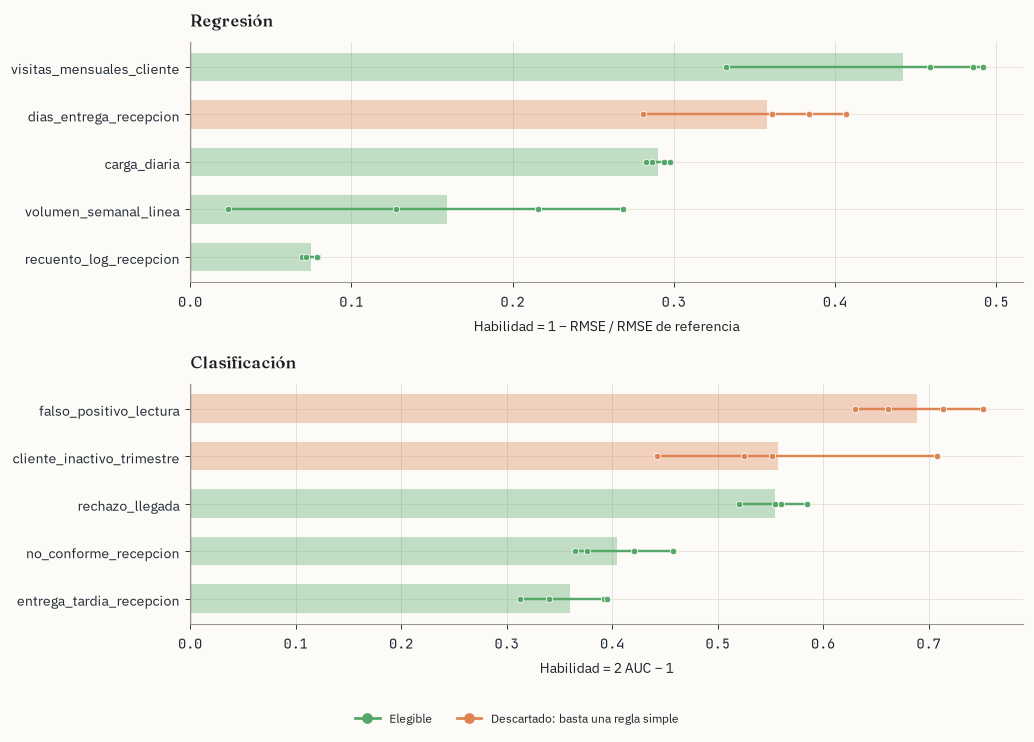

In [4]:
cribado.prueba_rapida(c).mostrar()

## 4. ¿Basta una regla simple?

Un modelo solo se justifica si combina información. Para comprobarlo entrenamos en cada bloque un árbol que ve una
sola variable (la que más aporta) y, si su habilidad llega al umbral frente al mejor modelo rápido, lo que
recomendaríamos es una regla operativa y no un modelo.

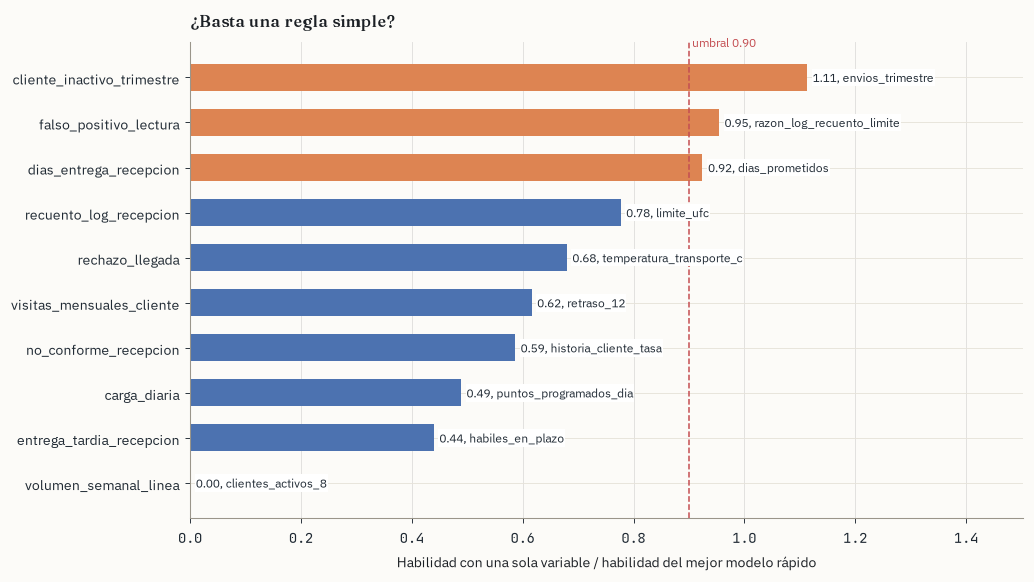

In [5]:
cribado.regla_simple(c).mostrar()

## 5. Candidatos de agrupamiento

Aquí no hay línea base que superar así que la prueba hace dos preguntas. La primera es si los datos tienden a
formar grupos, y la responde el estadístico de **Hopkins**: Compara qué tan cerca quedan los puntos reales de sus
vecinos frente a puntos puestos al azar y da cerca de 0.5 cuando no hay grupos y se acerca a uno cuando sí. La
segunda es qué tan separados quedan los grupos de K-means y la responde la **silueta**, que va de menos uno a uno
y es alta cuando cada punto está más cerca de los de su grupo que de los del grupo vecino.

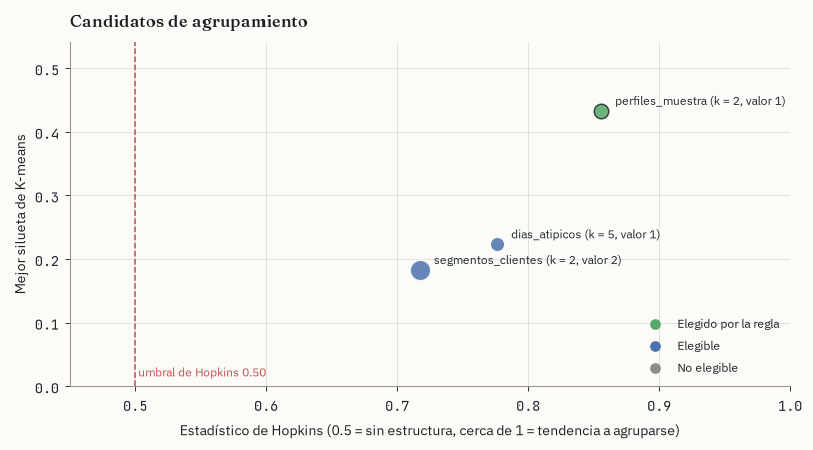

In [6]:
cribado.candidatos_agrupamiento(c).mostrar()

## 6. Selección

El embudo resume cuántos candidatos quedan en cada paso. Las comparaciones muestran los mejores puntajes de cada
tipo, incluidos los no elegibles, para que se vea qué dejamos de lado y por qué.

In [7]:
cribado.seleccion(c).mostrar()

Para ver con qué llega el clasificador elegido a la etapa 05 le preguntamos a su tabla qué momento declara, qué
variables usa y si la auditoría de fugas encontró algo:

In [8]:
from proyecto.reporte.html import fichas
from proyecto.variables.comunes import auditar_momentos

tabla, papeles = c.tablas_modelado[c.seleccion["clasificacion"]]
hallazgos = auditar_momentos(tabla, papeles)   # lista vacía: ninguna variable se conoce después del momento
mostrar(fichas(papeles["numericas"] + papeles["categoricas"],
               f"Predice en \"{papeles['momento']}\" con estas variables ({len(hallazgos)} hallazgos de fuga)"))

## 7. Lo que sigue

La selección no se toca después: Las etapas 04 a 06 leen lo que quedó en `artefactos/03_cribado.json`. La única
excepción, que dejamos declarada aquí, es un análisis de agrupamiento complementario sobre los clientes.

In [9]:
cribado.consecuencias(c).mostrar()

In [10]:
cribado.terminar(c)

← Anterior: [Etapa 02: Exploración](02_exploracion.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 04: Regresión](04_regresion.ipynb) →